# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [1]:
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


DIR_PROC = Path("..") / "data" / "processed"

## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [2]:
dataset = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["data_hora"])
print(dataset.describe())

                 data_hora  altura_onda(m)  velocidade  altura_chuva(mm)  \
count                  168      168.000000  168.000000        168.000000   
mean   2026-10-11 11:30:00        1.127976   22.119048          0.034524   
min    2026-10-08 00:00:00        0.900000   16.000000          0.000000   
25%    2026-10-09 17:45:00        1.000000   21.000000          0.000000   
50%    2026-10-11 11:30:00        1.100000   22.000000          0.000000   
75%    2026-10-13 05:15:00        1.200000   23.000000          0.000000   
max    2026-10-14 23:00:00        1.400000   28.000000          0.400000   
std                    NaN        0.127117    2.354279          0.071751   

       probabilidade(%)  altura_mare_interp(m)  coeficiente        hora  
count        168.000000             168.000000   168.000000  168.000000  
mean          16.369048               1.391872    85.714286   11.500000  
min            4.000000               0.266301    65.000000    0.000000  
25%           10.00

In [3]:
print(dataset[["altura_onda(m)", "velocidade"]].describe())
print(dataset["altura_onda(m)"].value_counts().sort_index())
print(dataset["velocidade"].value_counts().sort_index())
print(f"mediana do vento: {dataset["velocidade"].median()}")

       altura_onda(m)  velocidade
count      168.000000  168.000000
mean         1.127976   22.119048
std          0.127117    2.354279
min          0.900000   16.000000
25%          1.000000   21.000000
50%          1.100000   22.000000
75%          1.200000   23.000000
max          1.400000   28.000000
altura_onda(m)
0.9     2
1.0    62
1.1    32
1.2    40
1.3    23
1.4     9
Name: count, dtype: int64
velocidade
16.0     3
17.0     3
18.0     5
19.0     5
20.0    13
21.0    42
22.0    33
23.0    25
24.0    15
25.0     5
26.0    10
27.0     8
28.0     1
Name: count, dtype: int64
mediana do vento: 22.0


## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

In [4]:
mediana_vento = dataset["velocidade"].median()

def classificar(linha):
    onda = linha["altura_onda(m)"]
    vento = linha["velocidade"]
    if onda >= 1.3 and vento <= mediana_vento:
        return "ótima"
    elif onda >= 1.1 and vento <= mediana_vento + 2:
        return "boa"
    return "ruim"

dataset["label"] = dataset.apply(classificar, axis=1)
print(dataset["label"].value_counts())


display(pd.crosstab(dataset["hora"], dataset["label"]),pd.crosstab(dataset["periodo"], dataset["label"], normalize="index"))

label
boa      72
ruim     70
ótima    26
Name: count, dtype: int64


label,boa,ruim,ótima
hora,,,
0,2,4,1
1,3,3,1
2,3,3,1
3,3,3,1
4,4,3,0
5,3,4,0
6,3,4,0
7,5,2,0
8,4,2,1


label,boa,ruim,ótima
periodo,,,
madrugada,0.428571,0.476190,0.095238
manhã,0.547619,0.309524,0.142857
noite,0.285714,0.571429,0.142857
tarde,0.452381,0.309524,0.238095


**Regra da label:** 

Eu classifiquei cada uma das 168 horas em três categorias: ótimas, boas e ruins. As ótimas têm a altura da onda como maior ou igual a 1,3 m e velocidade do vento menor ou igual à mediana. As boas possuem a altura da onda maior ou igual a 1,1 e velocidade do vento menor ou igual à mediana + 2. Por último, as horas ruins englobam o resto dos casos de altura da onda e velocidade do vento.

Sobre a origem dos números: para as ondas, usei a mediana das alturas (1,1 m) para separar as horas boas (iguais ou acima desse valor) das ruins (abaixo dele), e 1,3 m, a segunda maior altura da janela, para definir as ótimas. Para o vento, usei a mediana das velocidades (22 km/h): as horas ótimas têm velocidade menor ou igual a ela, porque quanto menor o vento, melhor a experiência de surfar (uma suposição minha, declarada), e as boas têm velocidade menor ou igual à mediana + 2, pois 2 é o desvio padrão (2,35 km/h) arredondado. As horas ruins são todas as demais.

As variáveis que eu excluí da regra foram as seguintes:
- Direção do vento, pois todas as direções eram de ventos de mar para a terra;
- Chuva, pois o máximo da sua probabilidade era de 43% e todas as chuvas podem ser classificadas como fracas (máximo de 0,4 mm/h);
- Maré porque o seu melhor momento para surfar depende do pico, isto é, o lugar onde a onda quebra, informação essa que eu não tenho. Além disso, a maré não mostrou uma relação com a onda no EDA e a sua altura é interpolada.

Distribuição de classes:

- Ótimas: 26
- Boas: 72
- Ruins: 70Como os cortes vêm da distribuição desta semana, a classificação é relativa a ela. Por dia, as ótimas só aparecem entre 12 e 14/10 e as ruins se concentram entre 9 e 11/10, então a label depende mais do dia do que da hora.

Como os cortes vêm da distribuição desta semana, a classificação é relativa a ela. Por dia, as ótimas só aparecem entre 12 e 14/10 e as ruins se concentram entre 9 e 11/10, então a label depende mais do dia do que da hora.

## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [5]:
y = dataset["label"]

variaveis_numericas = [
    "altura_onda(m)", "velocidade", "altura_mare_interp(m)", "hora",
    "probabilidade(%)", "altura_chuva(mm)",]

variaveis_categoricas = ["direcao_vento", "mare_sentido"]

X = pd.get_dummies(dataset[variaveis_numericas + variaveis_categoricas], columns=variaveis_categoricas, dtype=int)



Tirei o coeficiente de maré das variáveis numéricas, pois ele tem um valor único por dia. Além disso, também retirei a direção da onda das variáveis categóricas porque ela variava muito pouco em um dia, mudando um pouco mais entre os dias.

## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [6]:
dia = dataset["data_hora"].dt.day
dias_teste = [9, 13]              
em_teste = dia.isin(dias_teste)

X_treino, X_teste = X[~em_teste], X[em_teste]
y_treino, y_teste = y[~em_teste], y[em_teste]

print(X_treino.shape, X_teste.shape)    
print(y_treino.value_counts())         
print(y_teste.value_counts())          

(120, 13) (48, 13)
label
boa      51
ruim     48
ótima    21
Name: count, dtype: int64
label
ruim     22
boa      21
ótima     5
Name: count, dtype: int64


## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [7]:
arvore = DecisionTreeClassifier(max_depth=4, random_state=42)
arvore.fit(X_treino, y_treino)

baseline = y_teste.value_counts(normalize=True).max()
print("Baseline (sempre a classe mais comum):", round(baseline, 2))
print("Árvore:", round(arvore.score(X_teste, y_teste), 2))

Baseline (sempre a classe mais comum): 0.46
Árvore: 1.0


In [8]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['boa','ruim','ótima']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['altura_onda(m)','velocidade','altura_mare_interp(m)',..., 'direcao_vento_SSE','mare_sentido_descendo','mare_sentido_subindo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

Baseline (sempre 'boa'): 0.44

=== Árvore: acurácia no teste = 1.00 ===
              precision    recall  f1-score   support

        ruim       1.00      1.00      1.00        22
         boa       1.00      1.00      1.00        21
       ótima       1.00      1.00      1.00         5

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48


=== KNN: acurácia no teste = 0.52 ===
              precision    recall  f1-score   support

        ruim       0.88      0.64      0.74        22
         boa       0.44      0.33      0.38        21
       ótima       0.25      0.80      0.38         5

    accuracy                           0.52        48
   macro avg       0.52      0.59      0.50        48
weighted avg       0.62      0.52      0.54        48



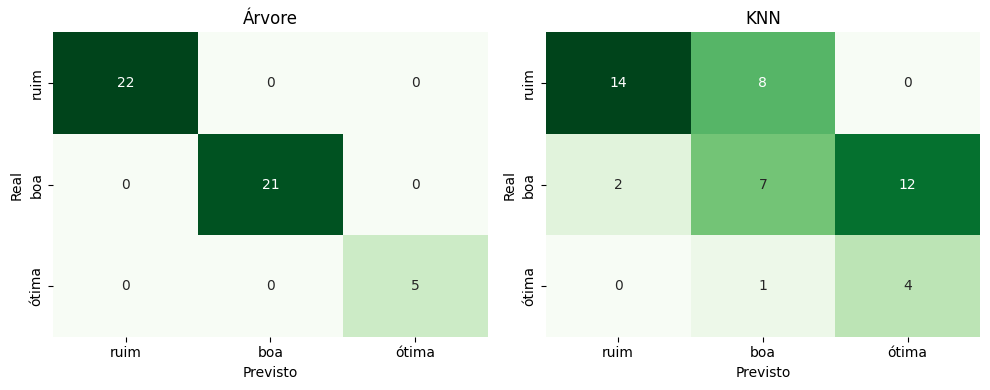

In [9]:
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score

classes = ["ruim", "boa", "ótima"]

mais_comum = y_treino.mode()[0]
print(f"Baseline (sempre '{mais_comum}'): {(y_teste == mais_comum).mean():.2f}")

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, modelo) in zip(eixos, [("Árvore", arvore), ("KNN", knn)]):
    pred = modelo.predict(X_teste)
    print(f"\n=== {nome}: acurácia no teste = {(pred == y_teste).mean():.2f} ===")
    print(classification_report(y_teste, pred, labels=classes, zero_division=0))

    matriz = confusion_matrix(y_teste, pred, labels=classes)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Greens", cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.show()


In [10]:
for nome, modelo in [("Árvore", arvore), ("KNN", knn)]:
    notas = cross_val_score(modelo, X, y, groups=dia, cv=LeaveOneGroupOut())
    print(f"{nome}: acurácia por dia = {notas.round(2)}  média = {notas.mean():.2f}")

Árvore: acurácia por dia = [1.   1.   1.   1.   1.   1.   0.75]  média = 0.96
KNN: acurácia por dia = [0.79 0.67 0.83 0.5  0.67 0.33 0.25]  média = 0.58


O teste tem só 48 horas, com 5 ótimas, então um erro nessa classe muda o recall em 20 pontos; por isso olhei também a matriz de confusão. A árvore acertou tudo (1,00, contra 0,44 do chute da classe mais comum do treino). O KNN ficou em 0,52 e errou quase sempre para cima: previu "ótima" em 12 das 21 horas boas e "boa" em 8 das 22 ruins (20 dos 23 erros), de modo que acertou 4 das 5 ótimas, mas rotulou 16 horas como ótimas (precisão de 0,25). Na validação cruzada por dia, a árvore teve 0,96 em média, com queda no dia 14 (0,75).

## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

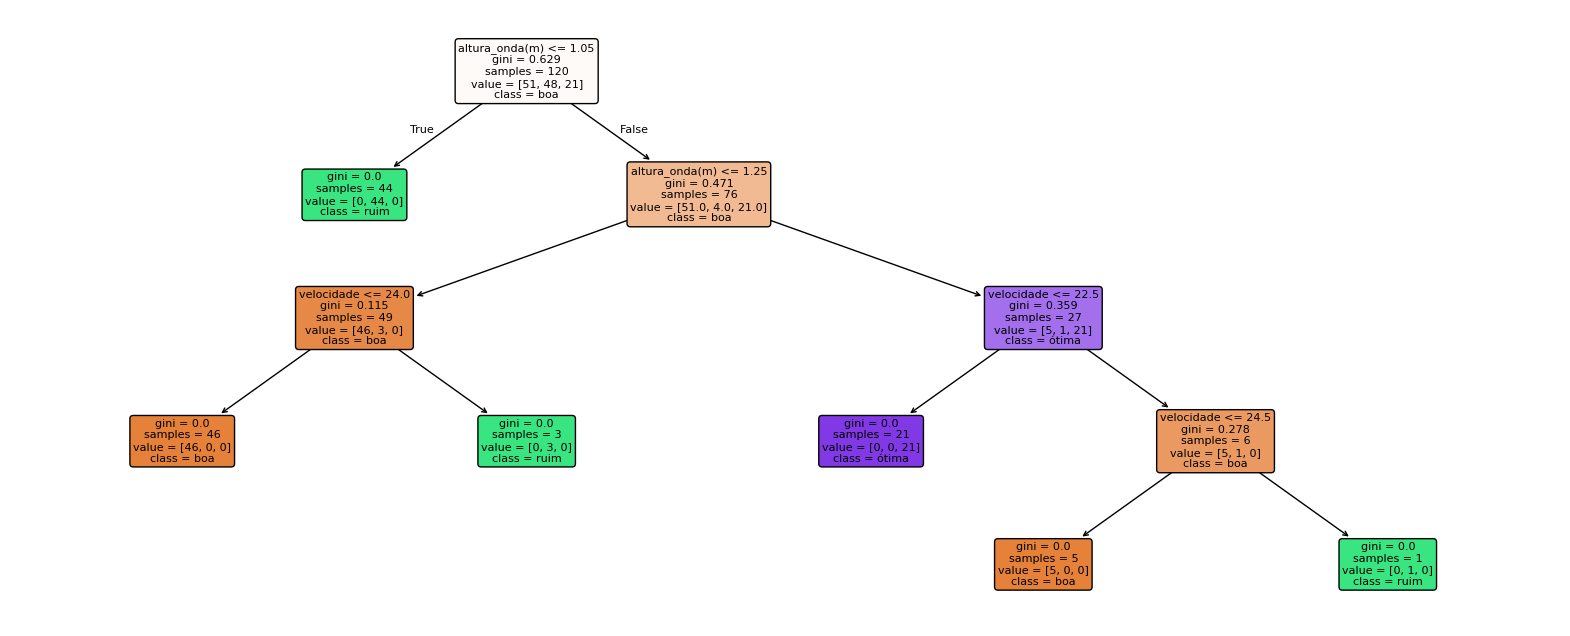

In [11]:
from sklearn.tree import export_text

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arvore, feature_names=list(X.columns), class_names=list(arvore.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

importancias = pd.Series(arvore.feature_importances_, index=X.columns).sort_values(ascending=False)

cols_regra = ["altura_onda(m)", "velocidade"]
arvore_regra = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_treino[cols_regra], y_treino)
acc = (arvore_regra.predict(X_teste[cols_regra]) == y_teste).mean()

In [12]:
print(importancias.round(3).head(8))
print("Árvore só com as 2 colunas da regra:", round(acc, 2))
print(export_text(arvore, feature_names=list(X.columns)))

altura_onda(m)           0.797
velocidade               0.203
altura_mare_interp(m)    0.000
hora                     0.000
probabilidade(%)         0.000
altura_chuva(mm)         0.000
direcao_vento_E          0.000
direcao_vento_ENE        0.000
dtype: float64
Árvore só com as 2 colunas da regra: 1.0
|--- altura_onda(m) <= 1.05
|   |--- class: ruim
|--- altura_onda(m) >  1.05
|   |--- altura_onda(m) <= 1.25
|   |   |--- velocidade <= 24.00
|   |   |   |--- class: boa
|   |   |--- velocidade >  24.00
|   |   |   |--- class: ruim
|   |--- altura_onda(m) >  1.25
|   |   |--- velocidade <= 22.50
|   |   |   |--- class: ótima
|   |   |--- velocidade >  22.50
|   |   |   |--- velocidade <= 24.50
|   |   |   |   |--- class: boa
|   |   |   |--- velocidade >  24.50
|   |   |   |   |--- class: ruim



In [13]:
cols_sem_regra = [c for c in X.columns if c not in ["altura_onda(m)", "velocidade"]]

arvore_sem = DecisionTreeClassifier(max_depth=4, random_state=42)
arvore_sem.fit(X_treino[cols_sem_regra], y_treino)
print("Sem as colunas da regra, no teste:", round(arvore_sem.score(X_teste[cols_sem_regra], y_teste), 2))

notas = cross_val_score(arvore_sem, X[cols_sem_regra], y, groups=dia, cv=LeaveOneGroupOut())
print("Por dia:", notas.round(2), "| média:", round(notas.mean(), 2))

Sem as colunas da regra, no teste: 0.42
Por dia: [0.5  0.5  0.38 0.38 0.38 0.25 0.21] | média: 0.37


A árvore usa só onda, com cerca de 80% da importância, e vento, com cerca de 20%, enquanto maré, hora, chuva e direção do vento têm importância zero. Seus cortes (onda ≤ 1,05 e ≤ 1,25 m e vento ≤ 22,5 e ≤ 24,0/24,5 km/h) são os limiares da minha regra no ponto médio entre valores vizinhos.

A acurácia de 1,00 no teste não significa que ela previu o mar, ela mostra que a label sai de onda e vento, que também são features, então a árvore só reencontrou o if que escrevi. Sem essas duas colunas, a acurácia cai para 0,42 no teste e 0,37 na validação cruzada, abaixo do chute (0,44): todo o desempenho vem de onda e vento.

O KNN (0,52) foi pior, provavelmente porque mede distância em 13 colunas, com a maioria sem relação com a regra (não testei só com onda e vento). A queda da árvore no dia 14 (0,75) ocorre porque, sem ele, o treino perde 18 das 26 ótimas.

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

In [14]:
nota = {"ruim": 0, "boa": 1, "ótima": 2}

dataset["previsao"] = arvore.predict(X)
dataset["nota"] = dataset["previsao"].map(nota)
dataset["dia"] = dataset["data_hora"].dt.day

por_dia = dataset.groupby("dia").agg(
    nota_media=("nota", "mean"),
    horas_otimas=("previsao", lambda s: (s == "ótima").sum()),
).round(2).sort_values("nota_media", ascending=False)
print(por_dia)

print(dataset.groupby("hora")["nota"].mean().round(2).sort_values(ascending=False).head(5))
print(dataset.groupby("periodo")["nota"].mean().round(2))

print("Concordância modelo x regra nas 168 horas:", round((dataset["previsao"] == dataset["label"]).mean(), 2))

     nota_media  horas_otimas
dia                          
14         1.71            18
13         1.12             5
12         1.08             3
8          0.71             0
10         0.38             0
9          0.17             0
11         0.00             0
hora
9     1.14
12    1.00
15    1.00
13    1.00
10    1.00
Name: nota, dtype: float64
periodo
madrugada    0.62
manhã        0.83
noite        0.57
tarde        0.93
Name: nota, dtype: float64
Concordância modelo x regra nas 168 horas: 1.0


- Quais os melhores dias da janela de previsão?

14/10 (nota média 1,71; 18 de 24 horas ótimas), 13/10 (1,12) e 12/10 (1,08). Os piores são 11/10 (0,00), 9/10 (0,17) e 10/10 (0,38). Todas as 26 horas ótimas estão entre 12 e 14/10.

- Em média, qual o melhor horário do dia?

A hora 9 tem a maior nota (1,14), seguida das horas 10, 12, 13, 14 e 15 (1,00). Por período, a tarde lidera (0,93), depois manhã (0,83), madrugada (0,62) e noite (0,57). O sinal é fraco: cada hora tem 7 observações, e como 18 das 26 ótimas estão no dia 14, a vantagem da tarde pode vir em boa parte dele (não verifiquei sem esse dia). Dentro de 14/10, o melhor horário é das 11h às 18h, com pico às 15h, segundo o índice do EDA (acima de 3).

- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a sua regra reescrita?

A concordância do modelo com a regra é de 1,00, então a resposta é a previsão do site filtrada pela minha regra; o modelo não acrescenta nada, e a previsão do mar eu não validei. Vale só para esta semana.

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.

1. Recomendação: 
Nesta janela, priorizar 14/10, das 11h às 18h (pico às 15h), com onda de 1,3 a 1,4 m e vento de até 22 km/h (o critério de "ótima" da minha regra), seguido de 13 e 12/10.

2. Teto do modelo: 
Ele reproduz a minha heurística, a qual possui uma concordância de 1,00 com a regra e uma acurácia de 0,37 na validação cruzada sem onda e vento. A regra melhoraria com a maré no pico certo, a direção do vento (sobretudo vento de terra, ausente na janela), o período da onda (que o site não traz por hora) e limiares validados com surfistas. O peso igual entre onda e vento é escolha minha.


3. Limites da janela:
São 168 horas, mas cerca de 7 observações independentes (a onda muda por dia). Não dá para afirmar um padrão por horário, nem que 14/10 é melhor por algo além da previsão (ele concentra 18 das 26 ótimas). Também há só 5 ótimas no teste, a onda vem em passos de 0,1 m e os dados são previsões.

4. Melhor época do ano: 
Não dá para responder com 7 dias de previsão. Faltaria um histórico longo de onda e vento, de preferência com alguma medida de qualidade observada, obtido rodando o scrape.py diariamente ou buscando séries históricas para João Pessoa. A tábua de marés de 2025 existe, mas sozinha não diz nada sobre as ondas.